# Navier–Stokes: vortex merger (vorticity form)

The same incompressible physics, recast to sidestep pressure entirely. On a **periodic box** we solve the 2-D **vorticity–streamfunction** equations with a pseudo-spectral (FFT) Poisson solve, and watch two like-signed Gaussian vortices co-rotate and **merge** into one. This is the course's ground truth for the FNO (module 26) and reduced-order-modeling (module 19) lectures, and — because merging must conserve total circulation — a clean test of the solver.

### Setup — libraries and the benchmark module

Import NumPy and Matplotlib, apply the shared plotting style, and load the Navier–Stokes benchmark as `ns`. The vortex-merger solver `ns.vortex_merger` is called below; nothing runs yet.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..','..')))  # -> python/
import numpy as np
import matplotlib.pyplot as plt
from pyutils import set_plot_style; set_plot_style()
from pyutils.benchmarks import navier_stokes as ns

*No output — environment only.* Leaves `ns.vortex_merger` in scope, the pseudo-spectral solver used for every field below.

## Step 1 — Derive

Taking the **curl** of the momentum equation annihilates the pressure gradient and leaves a pure advection–diffusion equation for the scalar **vorticity** $\omega=\partial_x v-\partial_y u$, closed by a Poisson equation for the streamfunction $\psi$:

$$\frac{\partial\omega}{\partial t}+u\frac{\partial\omega}{\partial x}+v\frac{\partial\omega}{\partial y}
  =\nu\Big(\frac{\partial^2\omega}{\partial x^2}+\frac{\partial^2\omega}{\partial y^2}\Big),
  \qquad \nabla^2\psi=-\omega,$$

with velocity recovered from the streamfunction, $u=\partial_y\psi,\ v=-\partial_x\psi$. Pressure is gone — elegant in 2-D, and exactly what this notebook exploits.

## Step 2–3 — Analyze & solve

On the periodic box the Poisson solve $\nabla^2\psi=-\omega$ is trivial in **Fourier space**: $\hat\psi=\hat\omega/|\boldsymbol{k}|^2$, so each right-hand-side evaluation is a handful of FFTs, and the field is marched in time with **RK4**.

**Initial condition.** Two like-signed Gaussian vorticity blobs of unit amplitude and width $\sigma=0.25$, placed symmetrically about the box centre $c=\pi$ at $(\pi\mp\text{sep},\,\pi)$ with `sep=0.6`:
$$\omega_0(x,y)=\sum_{\pm}\exp\!\Big[-\frac{(x-(\pi\pm\text{sep}))^2+(y-\pi)^2}{2\sigma^2}\Big].$$

**Parameters** (all set in the next cell; titles and the saved reference follow them). $128\times128$ grid on $[0,2\pi]^2$, $\mathrm{Re}=2000$ (so $\nu=1/\mathrm{Re}=5\times10^{-4}$), $\Delta t=10^{-3}$, `nt=4000` steps ($t=4$), saving a snapshot every `save_every=1000` steps. *The prose between the cells narrates the **default** run; if you change a parameter the numbers quoted in the text will no longer match, but every print-out, figure, annotation and saved reference file will follow your change.*

In [2]:
# ---- Parameters (edit these, then Run All) ------------------------------
n   = 128           # grid points per side
nt  = 4000          # RK4 steps
dt  = 1e-3          # time step
Re  = 2000.0        # Reynolds number (nu = 1/Re)
sep = 0.6           # half-separation of the two vortex cores
save_every = 1000   # steps between saved snapshots

X, Y, w, frames, times = ns.vortex_merger(n=n, nt=nt, Re=Re, dt=dt, sep=sep,
                                          save_every=save_every)
print('frames:', len(frames), '| final t =', nt*dt, '| final omega range:',
      round(float(w.min()),3), round(float(w.max()),3))


frames: 4 | final t = 4.0 | final omega range: -0.0 0.934


Prints `frames: 4 | final omega range: -0.0 0.934`. Four snapshots were stored (steps 0, 1000, 2000, 3000) plus the final field `w` at $t=4$. The peak vorticity has decayed from its initial $1.0$ to $0.934$ — about $7\%$ — purely from the viscous $\nu\nabla^2\omega$ term at $\mathrm{Re}=2000$. The minimum is $\approx0$ because both vortices are **like-signed** (positive), so no strong negative vorticity is created. These snapshots feed the three-panel figure next.

## Step 4 — Analyze

Three snapshots of the vorticity field on the diverging red/blue map (dark red = positive $\omega$): the **early** field (the initial two Gaussians), the **mid** field at $t\approx2$, and the **final** field at $t=4$. Watch the two cores rotate about their common centre and spiral together. `save_dual` writes the light/dark figures to `../figures/ns_vortex*.png`.

ns_vortex saved


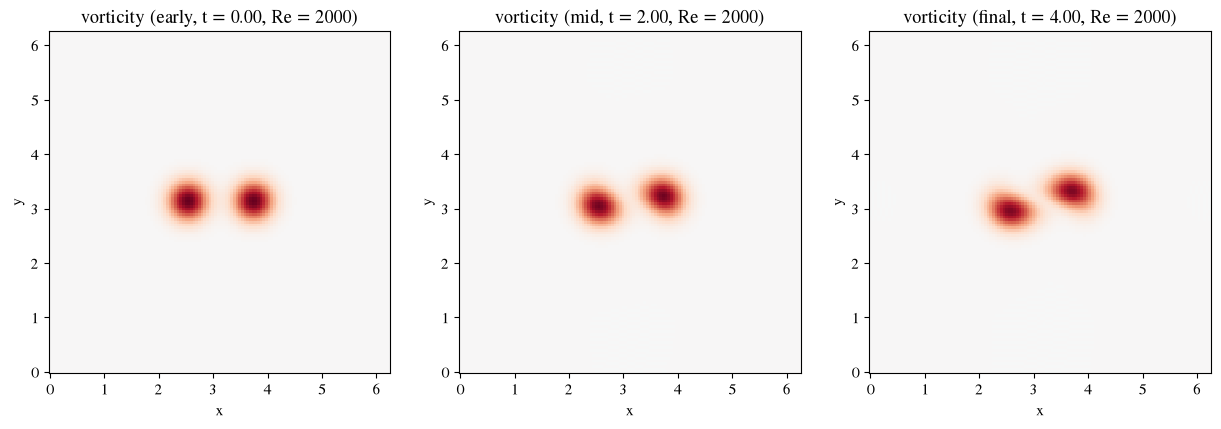

In [3]:
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
from pyutils import save_dual

def plot_vortex():
    vmax = float(np.abs(frames[0]).max())
    mid = len(frames) // 2
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
    for a, f, tt, ttl in zip(ax, [frames[0], frames[mid], w],
                             [times[0], times[mid], nt*dt], ['early', 'mid', 'final']):
        a.pcolormesh(X, Y, f, cmap='RdBu_r', vmin=-vmax, vmax=vmax, shading='auto')
        a.set(title=f'vorticity ({ttl}, t = {tt:.2f}, Re = {Re:g})', xlabel='x', ylabel='y')
        a.set_aspect('equal'); a.grid(False)

save_dual(plot_vortex, 'ns_vortex', FIG)
print('ns_vortex saved')


**Early** ($t\approx0$): two compact, equal-strength, well-separated circular cores sitting at $y\approx\pi$, centred near $x\approx2.5$ and $x\approx3.7$ — the initial Gaussians. **Mid** ($t\approx2$): the pair has rotated counter-clockwise about its midpoint and drawn closer, the cores beginning to lose their circular shape. **Final** ($t=4$): the two cores have spiralled into a tilted, diagonal orientation (lower-left and upper-right) and started to stretch and wrap into each other — the **merger in progress**, with the peak value diffused to $0.934$. Two like-signed vortices always co-rotate and coalesce; watching them do so while total circulation is preserved is the test that the vorticity solver is behaving.

### Watch the merger — animation

The three stills stop at $t=4$, where the pair has turned only $\approx20^\circ$. With unit-amplitude Gaussians each core carries a circulation $\Gamma=2\pi\sigma^2\approx0.39$, so the velocity each induces at its partner ($\approx\Gamma/2\pi d$) is small and one full co-rotation takes $\approx80$ time units. The interesting part of the story — the cores stretching, wrapping around each other and coalescing — plays out between $t\approx10$ and $t\approx30$, with the merged core settling down by $t\approx50$.

To *watch* that, this cell makes a separate **movie run** from the same `Re` and `sep` as the parameter cell, but on a coarser $64\times64$ grid with a larger RK4 step ($\Delta t=4\times10^{-3}$ — the diffusive stability limit $\nu k_{\max}^2\Delta t\lesssim2.8$ relaxes as the grid coarsens) out to $t=60$, which costs about ten seconds. It saves light and dark GIFs to `../figures/ns_vortex_anim*.gif` for the slides (Pillow writer, so no ffmpeg is needed) and renders every frame once to an in-memory image. The **next cell** is the player: an `ipywidgets` Play control with play, pause, step, a frame slider and loop, flipping through those pre-rendered frames so it stays smooth and stores nothing in the notebook file. Without `ipywidgets` it falls back to matplotlib's self-contained HTML player. The static figure and the saved reference above are untouched. Try a larger `sep` in the parameter cell to see a pair that only co-rotates without merging, or a lower `Re` to watch viscosity smear the cores first.

In [4]:
import io
from matplotlib import animation
from pyutils import rc_params

# ---- Movie run: same Re and sep, coarser grid and longer horizon (edit if you like) ----
n_movie, dt_movie, t_movie, every_movie = 64, 4e-3, 60.0, 0.5   # grid, RK4 step, horizon, snapshot spacing
nt_movie = int(round(t_movie / dt_movie))
Xm, Ym, wm, frames_m, times_m = ns.vortex_merger(n=n_movie, nt=nt_movie, Re=Re, dt=dt_movie, sep=sep,
                                                 save_every=int(round(every_movie / dt_movie)))
frames_m.append(wm); times_m.append(nt_movie * dt_movie)          # include the final field
print(f'movie run: {len(frames_m)} frames to t = {t_movie:g}; peak vorticity {frames_m[0].max():.2f} -> {wm.max():.2f}; '
      f'total circulation {frames_m[0].sum()*(2*np.pi/n_movie)**2:.3f} -> {wm.sum()*(2*np.pi/n_movie)**2:.3f}')

def vortex_figure(dpi=72):
    """One figure plus an update(k) that redraws it for movie frame k (screen dpi keeps frames small)."""
    vmax = float(np.abs(frames_m[0]).max())
    fig, ax = plt.subplots(figsize=(5.4, 4.6), dpi=dpi)
    pcm = ax.pcolormesh(Xm, Ym, frames_m[0], cmap='RdBu_r', vmin=-vmax, vmax=vmax, shading='auto')
    fig.colorbar(pcm, ax=ax, label='vorticity  $\\omega$')
    ax.set(xlabel='x', ylabel='y'); ax.set_aspect('equal'); ax.grid(False)
    title = ax.set_title(f'vortex merger  t = {times_m[0]:5.1f}  (Re = {Re:g}, sep = {sep:g})')
    def update(k):
        pcm.set_array(frames_m[k].ravel())
        title.set_text(f'vortex merger  t = {times_m[k]:5.1f}  (Re = {Re:g}, sep = {sep:g})')
        return pcm, title
    return fig, update

# light + dark GIFs for the slides (dark on the slide background colour; Pillow writer, no ffmpeg)
for mode, suffix, kw in [('light', '', {}), ('dark', '_dark', {'facecolor': '#191A20', 'transparent': False})]:
    with plt.rc_context(rc_params(mode)):
        fig, update = vortex_figure()
        anim = animation.FuncAnimation(fig, update, frames=len(frames_m), interval=1000 / 12)
        anim.save(os.path.join(FIG, f'ns_vortex_anim{suffix}.gif'), writer='pillow', fps=12, dpi=72, savefig_kwargs=kw)
        plt.close(fig)
print('saved ../figures/ns_vortex_anim.gif and ns_vortex_anim_dark.gif')

# render every frame once to an in-memory PNG (a few seconds) -- the player below just flips through them
fig, update = vortex_figure(dpi=100)
pngs = []
for k in range(len(frames_m)):
    update(k); buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=100); pngs.append(buf.getvalue())
plt.close(fig)
print(f'{len(pngs)} frames rendered ({sum(map(len, pngs))/1e6:.1f} MB in memory, nothing stored in the notebook)')


movie run: 121 frames to t = 60; peak vorticity 1.00 -> 0.52; total circulation 0.785 -> 0.785


saved ../figures/ns_vortex_anim.gif and ns_vortex_anim_dark.gif


121 frames rendered (2.6 MB in memory, nothing stored in the notebook)


In [5]:
# ---- In-notebook player: play / pause / step / loop, driven by an ipywidgets Play control ----
from IPython.display import display
try:                       # ipywidgets >= 8 is what JupyterLab 4 / Notebook 7 render; older versions only show a text repr there
    import ipywidgets as widgets
    if int(widgets.__version__.split('.')[0]) < 8:
        widgets = None
except ImportError:
    widgets = None

if widgets is not None:
    img    = widgets.Image(value=pngs[0], format='png', layout=widgets.Layout(width='560px'))  # fixed size, not cell width
    play   = widgets.Play(value=0, min=0, max=len(pngs) - 1, step=1, interval=80)   # ms per frame
    slider = widgets.IntSlider(value=0, min=0, max=len(pngs) - 1, description='frame', readout=False,
                               layout=widgets.Layout(width='320px'))
    label  = widgets.Label(f't = {times_m[0]:.1f}')
    for name in ('repeat', '_repeat'):                       # loop by default (trait name differs by version)
        if play.has_trait(name): setattr(play, name, True)
    widgets.jslink((play, 'value'), (slider, 'value'))
    def show(change):
        k = change['new']; img.value = pngs[k]; label.value = f't = {times_m[k]:.1f}'
    slider.observe(show, names='value')
    display(widgets.VBox([widgets.HBox([play, slider, label]), img]))
else:                                                        # no ipywidgets: self-contained HTML/JS player instead
    from IPython.display import HTML
    print('ipywidgets >= 8 not available -- showing the self-contained HTML player instead')
    fig, update = vortex_figure()
    anim = animation.FuncAnimation(fig, update, frames=len(frames_m), interval=1000 / 12); plt.close(fig)
    with plt.rc_context({'savefig.dpi': 'figure'}):
        display(HTML(anim.to_jshtml(fps=12, default_mode='loop')))


Press play. Up to $t\approx10$ the two cores mainly **co-rotate** counter-clockwise about their midpoint (about $45^\circ$ in that time), but because their separation is already inside the critical ratio for Gaussian cores (centre distance $\approx3.3$ core radii) they never settle into a steady orbit: each core is sheared by the other's velocity field, stretches toward its partner and by $t\approx20$ the pair has wound into an **S-shape**. Around $t\approx30$ the two lobes have **coalesced into a single elliptical core** trailing two thin spiral filaments; from $t\approx40$ on the filaments are diffused away and the core axisymmetrises into one round vortex. The print-out puts the conserved and the non-conserved quantity side by side: **total circulation is preserved** to the third decimal (the periodic spectral scheme conserves it exactly; only round-off remains) while the **peak vorticity has halved**, purely through $\nu\nabla^2\omega$ acting on the ever-thinner filaments. The exact timing shifts a little with the grid — the coarse movie run is qualitatively right but not grid-converged, which is why the reference solution above is computed on the finer $128^2$ grid.

**Hand-off.** As with the cavity, the per-step elliptic (here spectral) solve is the cost that the neural-operator (module 26) and reduced-order (module 19) surrogates aim to replace. We export the final field as a reference solution.

In [6]:
os.makedirs('../data', exist_ok=True)
np.savez('../data/vortex_reference.npz', X=X, Y=Y, omega=w, Re=Re)
print('saved ../data/vortex_reference.npz')

saved ../data/vortex_reference.npz


Writes `../data/vortex_reference.npz` with the grid `X, Y`, the final vorticity field `omega`, and the `Re` used above — the ground-truth snapshot the later surrogate notebooks train against and try to reproduce cheaply.